# Prediksi Student Placement Menggunakan Algoritma Decision Tree

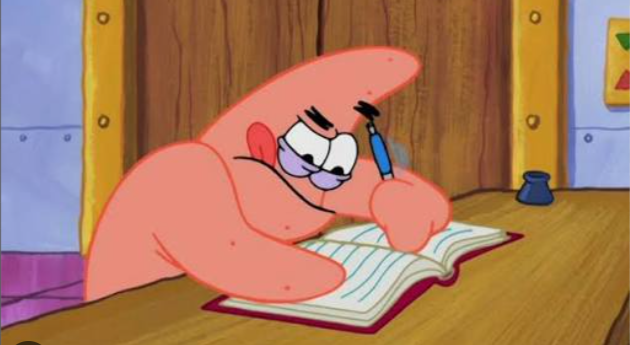

# A. DATA PREPARATION

A1. Import library

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

A2. Menambahkan dataset

In [2]:
df = pd.read_csv('student_dataset_10000_rows.csv')

A3. Melihat 5 data teratas

In [3]:
df.head()

,study_hours,attendance,sleep_hours,internet_usage,assignments_completed,previous_score,exam_score,placement_status
0,7,56,8,7,10,62,100.00,Placed
1,4,69,5,3,8,56,100.00,Placed
2,11,60,7,6,10,45,100.00,Placed
3,8,99,9,8,4,55,90.17,Placed
4,5,52,8,6,8,40,78.82,Placed


A4. Melihat informasi dari dataset

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   study_hours            10000 non-null  int64  
 1   attendance             10000 non-null  int64  
 2   sleep_hours            10000 non-null  int64  
 3   internet_usage         10000 non-null  int64  
 4   assignments_completed  10000 non-null  int64  
 5   previous_score         10000 non-null  int64  
 6   exam_score             10000 non-null  float64
 7   placement_status       10000 non-null  str    
dtypes: float64(1), int64(6), str(1)
memory usage: 625.1 KB


Berdasarkan hasil di atas :

- Fitur yang berisi numerik sudah terbaca Float atau Int
- Fitur yang berisi teks sudah terbaca str

hal ini menandakan bahwa dataset sudah rapi, tapi kami akan menganalisis lebih lanjut agar dataset benar-benar sudah rapi atau belum

A5. Melihat data kosong

In [5]:
df.isna().sum()

study_hours              0
attendance               0
sleep_hours              0
internet_usage           0
assignments_completed    0
previous_score           0
exam_score               0
placement_status         0
dtype: int64

Berdasarkan hasil di atas tidak ada fitur yang terindikasi data kosong

A6. Melihat data duplikat

In [6]:
def cek_duplikat(df):
    duplicated_df = df.duplicated()
    dup_sum = duplicated_df.sum()
    index_list = duplicated_df.index.to_list()
    print('Data yang terindikasi duplikat :')
    print(duplicated_df)
    print(f'Jumlah baris yang terduplikat : {dup_sum}')
    print(f'Baris : {index_list}')

In [7]:
cek_duplikat(df)

Data yang terindikasi duplikat :
0       False
1       False
2       False
3       False
4       False
        ...  
9995    False
9996    False
9997    False
9998    False
9999    False
Length: 10000, dtype: bool
Jumlah baris yang terduplikat : 0
Baris : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170

Berdasarkan hasil di atas tidak ada fitur yang terindikasi data duplikat

A7. Melihat isi dari kolom beritpe numerik

In [8]:
for num in df.select_dtypes(include=['int64', 'float64']).columns:
    print(f'{num} :')
    print(df[num].unique())
    print('_'*20)

study_hours :
[ 7  4 11  8  5 10  3  6  2  1  9]
____________________
attendance :
[ 56  69  60  99  52  40  86  72  77  64  65  98  67  76  80  96  88  87
  47  95  51  44  63  45  71  81  42  58  82  68  89  41  48  85  75 100
  59  43  54  55  50  94  93  73  61  90  66  49  97  70  84  74  92  46
  91  83  79  78  57  62  53]
____________________
sleep_hours :
[8 5 7 9 4 6]
____________________
internet_usage :
[ 7  3  6  8 10 11  5  9  2  4  1]
____________________
assignments_completed :
[10  8  4  0  9  7 18 15 12 17  3 13  6 11 14 19 16  5 20  1  2]
____________________
previous_score :
[62 56 45 55 40 60 50 85 48 69 76 87 89 70 36 47 46 67 43 78 41 51 95 44
 72 93 73 80 59 61 64 77 68 66 92 75 57 63 35 54 53 91 82 88 49 58 74 90
 84 81 39 83 38 65 37 42 71 52 86 94 79]
____________________
exam_score :
[100.    90.17  78.82 ...  86.47  69.31  95.94]
____________________


A8. Melihat isi dari kolom bertipe kategorikal

In [9]:
for uni in df.select_dtypes(include=['object', 'str']).columns:
    print(f'{uni} :')
    print(df[uni].unique())
    print('_'*20)

placement_status :
<StringArray>
['Placed', 'Not Placed']
Length: 2, dtype: str
____________________


A9. Melihat statistik deskriptif data

In [10]:
df.describe()

,study_hours,attendance,sleep_hours,internet_usage,assignments_completed,previous_score,exam_score
count,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000
mean,5.989600,69.88460,6.498500,6.062600,9.988400,64.91100,86.704207
std,3.163589,17.61653,1.709354,3.138163,6.034145,17.50302,15.058383
min,1.000000,40.00000,4.000000,1.000000,0.000000,35.00000,26.670000
25%,3.000000,55.00000,5.000000,3.000000,5.000000,50.00000,76.727500
50%,6.000000,70.00000,6.500000,6.000000,10.000000,65.00000,92.120000
75%,9.000000,85.00000,8.000000,9.000000,15.000000,80.00000,100.000000
max,11.000000,100.00000,9.000000,11.000000,20.000000,95.00000,100.000000


Berdasarkan hasil di atas :

- Kolom Exam_score memiliki rata-rata sebesar 86.70 dan median 92.12 sedangkan nilai minimal hingga Q3 hanya 26.67 hingga 100, hal ini perlu kami analisis lebih lanjut karena terdapat indilasi penumpukan nilai pada batas maksimum.
- Kolom Attendance memiliki rata-rata kehadiran sebesar 69.88%, Hal ini menunjukan bahwa tingkat kehadiran siswa secara umum masih perlu diperhatikan
- Kolom Study_hours memiliki nilai maksimum 11 jam belajar, nilai ini cukup tinggi sehingga perlu kami analisis lebih lanjut apakah terdapat siswa dengan waktu belajar yang sangat panjang.
- Kolom Internet_usage memiliki nilai maksimum 11 jam penggunaan internet, hal ini menarik untuk kami analisi lebih lanjut untuk mengetahui pola penggunaan internet siswa.

A10. Encode placement_status

In [11]:
df_enc = df.copy()
df_enc['placement_status'] = df_enc['placement_status'].map({
    'Placed':1,
    'Not Placed':0
})

# B. EDA

B1. Menampilkan Histplot untuk melihat distribusi data

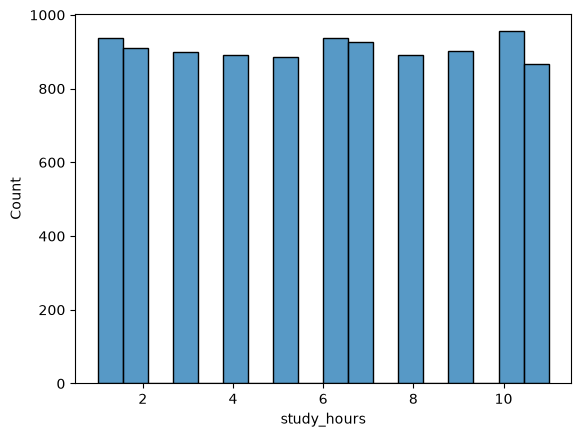

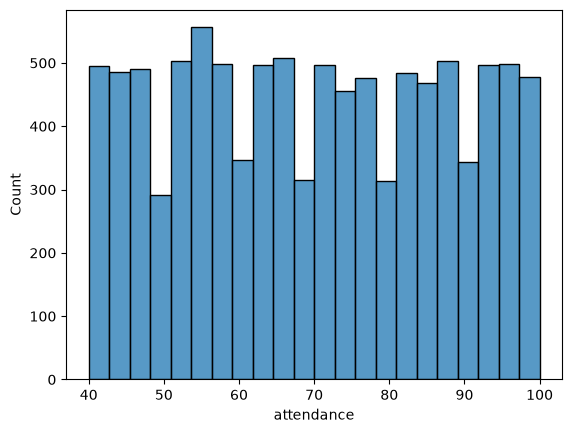

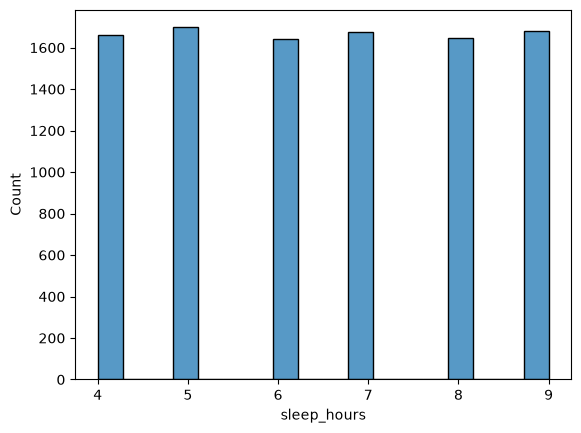

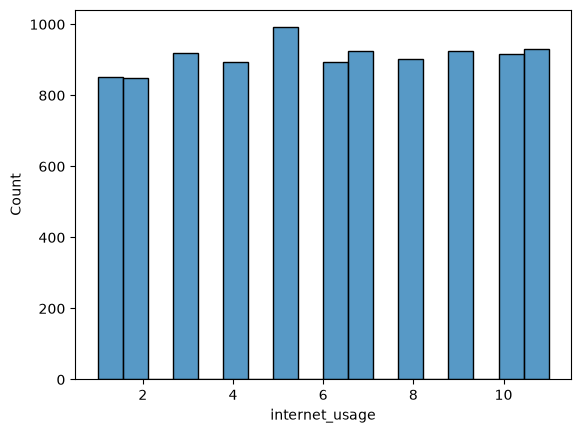

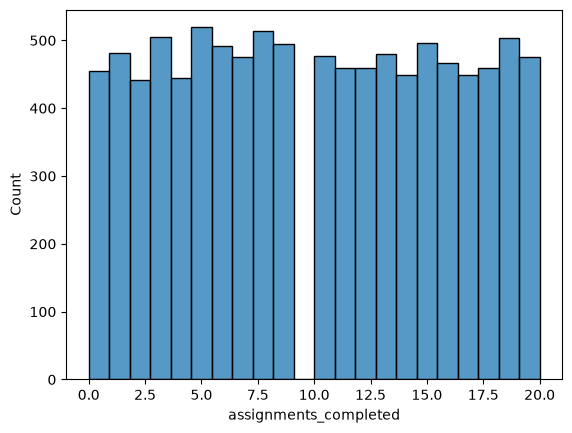

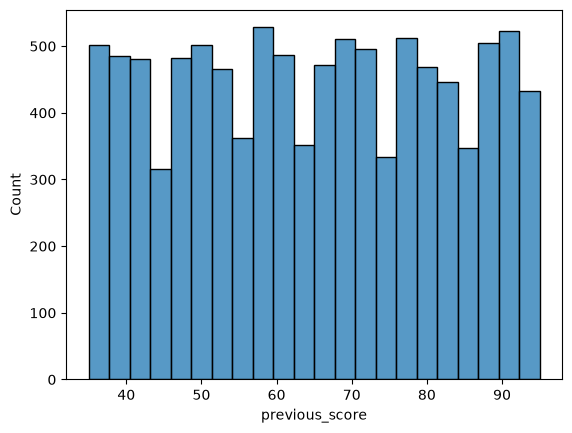

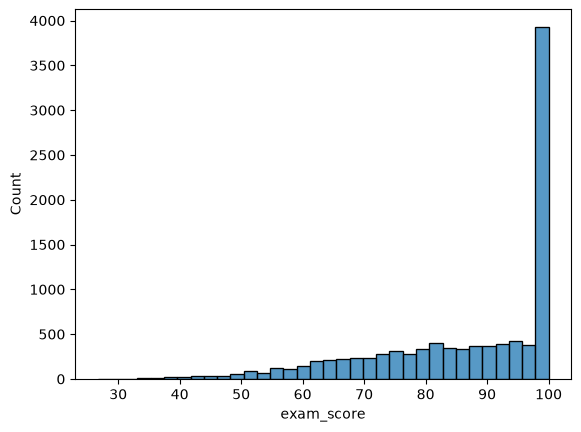

In [12]:
for i in df.select_dtypes(include=np.number).columns:
    sns.histplot(df[i])
    plt.show()

Berdasarkan hasil di atas kolom exam_score terindikasi penumpukan nilai pada batas maksimum yang menyebabkan hasil distribusinya cenderung miring ke kiri, hal ini perlu kami analisis lebih lanjut

B2. Menampilkan boxplot untuk melihat apakah ada outlier atau tidak

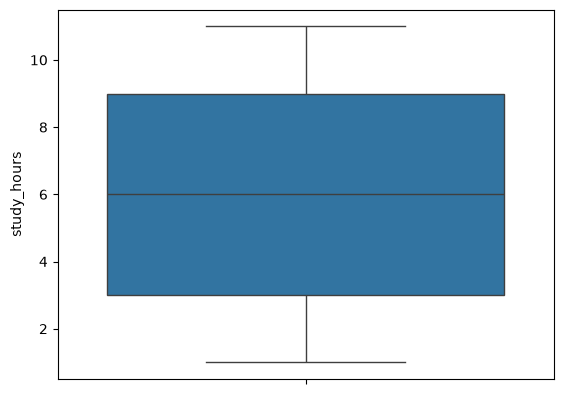

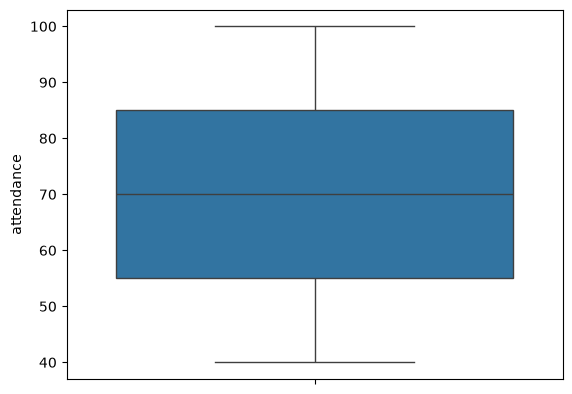

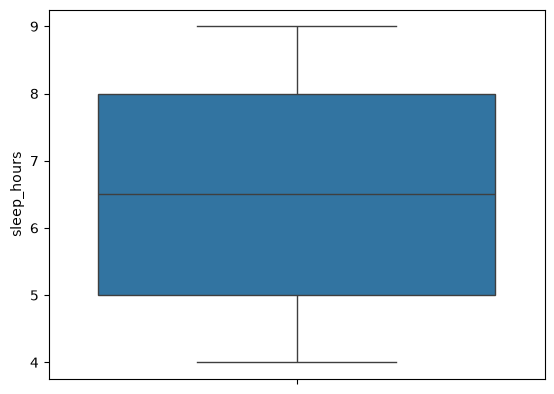

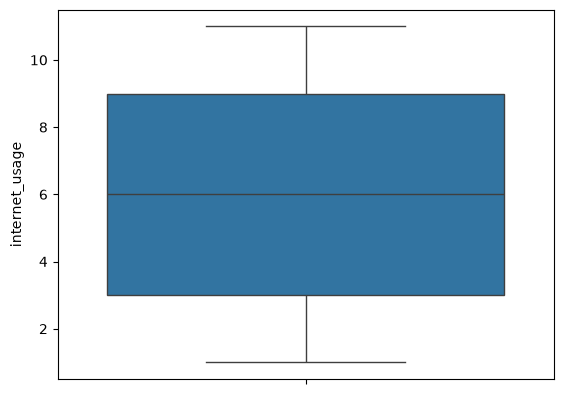

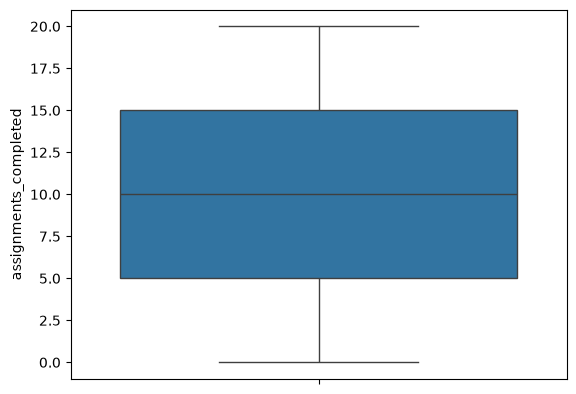

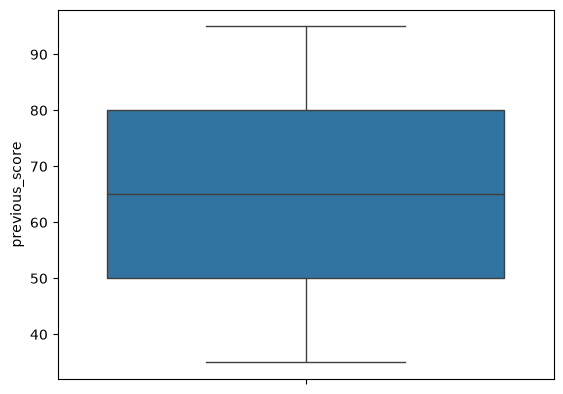

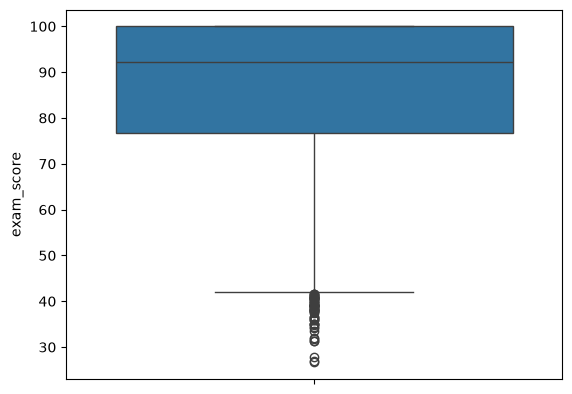

In [13]:
for i in df.select_dtypes(include=np.number).columns:
    sns.boxplot(df[i])
    plt.show()

Berdasarkan hasil di atas terindikasi fitur exam_score memiliki titik-titik outlier, namun indikasi tersebut tidak bisa dibilang outlier karena titik-titik tersebut masih berada pada skala yang normal, tidak ada yang melebihi 100 dan kurang dari 0. Alasan karena titik-titk tersebut dianggap outlier oleh boxplot karena berada di luar IQR namun titik-titik tersebut tetap valid.

B3. Menampilkan countplot untuk melihat distribusi kategori

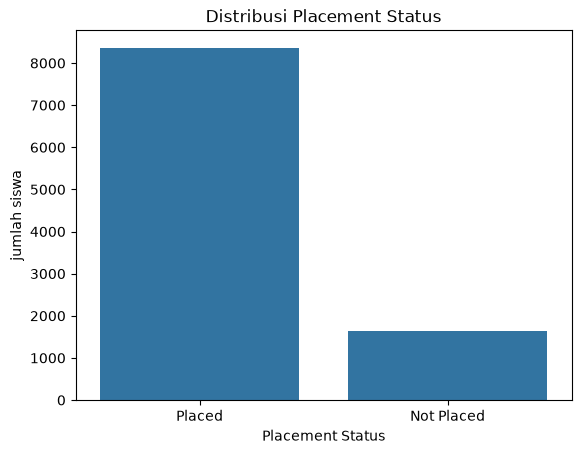

In [14]:
sns.countplot(data=df, x='placement_status')

plt.title('Distribusi Placement Status')
plt.xlabel('Placement Status')
plt.ylabel('jumlah siswa')
plt.show()

In [15]:
df['placement_status'].value_counts(normalize=True) * 100

placement_status
Placed        83.56
Not Placed    16.44
Name: proportion, dtype: float64

Berdasarkan hasil di atas sebagian besar jumlah siswa mendapatkan Placed dan sebagian kecil siswa mendapatkan Not Placed, sehingga hal ini dapat mempengaruhi hasil model hanya bisa memprediksi model mayoritas saja 

B4. Menampilkan scatterplot untuk melihat antar fitur

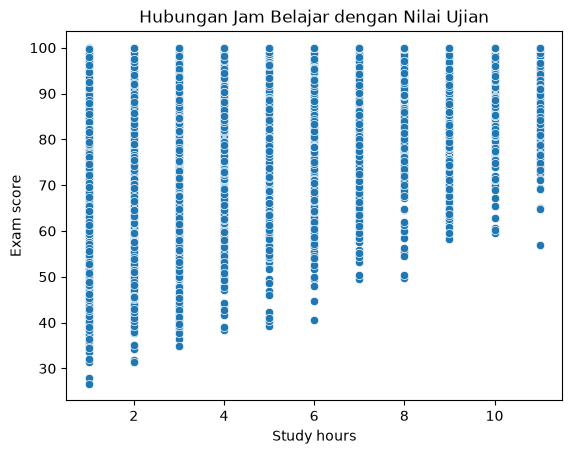

In [16]:
sns.scatterplot(data=df, x='study_hours', y='exam_score')
plt.title('Hubungan Jam Belajar dengan Nilai Ujian')
plt.xlabel('Study hours')
plt.ylabel('Exam score')
plt.show()

Berdasarkan hasil di atas :
- Siswa dengan jam belajar 9-11 jam memiliki rata-rata nilai ujian yang relatif tinggi
- Siswa dengan jam belajar lebih rendah cenderung memiliki nilai ujian yang lebih rendah

Namun, hubungan tersebut tidak secara langsung membuktikan bahwa peningkatan jam belajar menyebabkan peningkatan nilai ujian.

B5. Menampilkan barplot untuk melihat rata-rata setiap fitur berdasarkan status

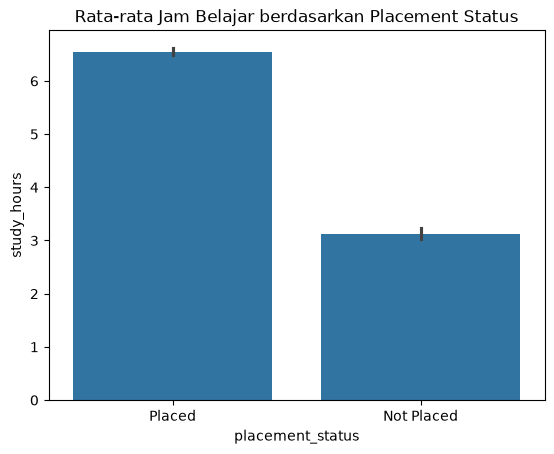

In [17]:
sns.barplot(data=df, x='placement_status', y='study_hours')
plt.title('Rata-rata Jam Belajar berdasarkan Placement Status')
plt.show()

Berdasarkan hasil di atas sama seperti hubungan dengan study_hours dengan exam_score, Siswa dengan jam belajar tinggi relatif mendapatkan Placed, Siswa dengan jam belajar rendah relatif mendapatkan Not Placed, hal ini mengindikasi bahwa jam belajar sangat berpengaruh untuk mendapatkan Placed atau Not Placed

B6. Menampilkan Heatmap untuk melihat korelasi antar fitur

<Axes: >

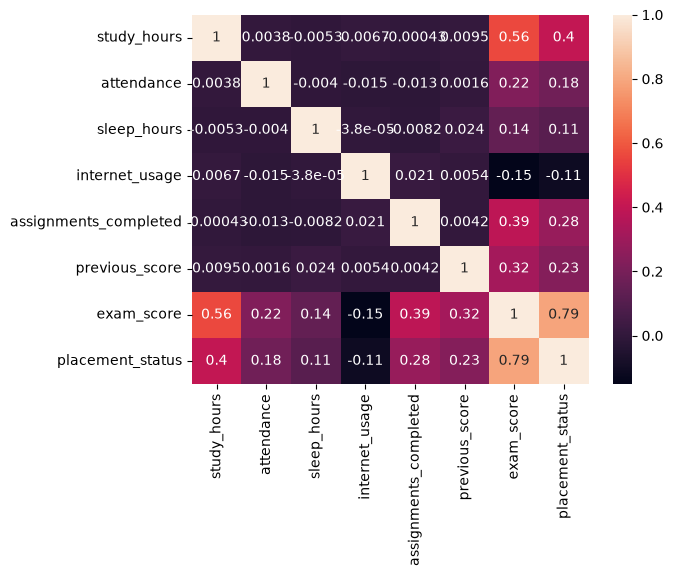

In [18]:
sns.heatmap(df_enc.corr(method='pearson'), annot=True)

Berdasarkan hasil di atas 
- korelasi antara exam_score dengan placement_status berada di 0.79, hal ini mengindikasikan bahwa exam_score berpengaruh terhadap placement_status
- korelasi antara study_hours dengan exam_score berada di 0.56, hal ini mengindikasi bahwa study hours ada hubungan dengan exam_score

B7. Menampilkan pairplot

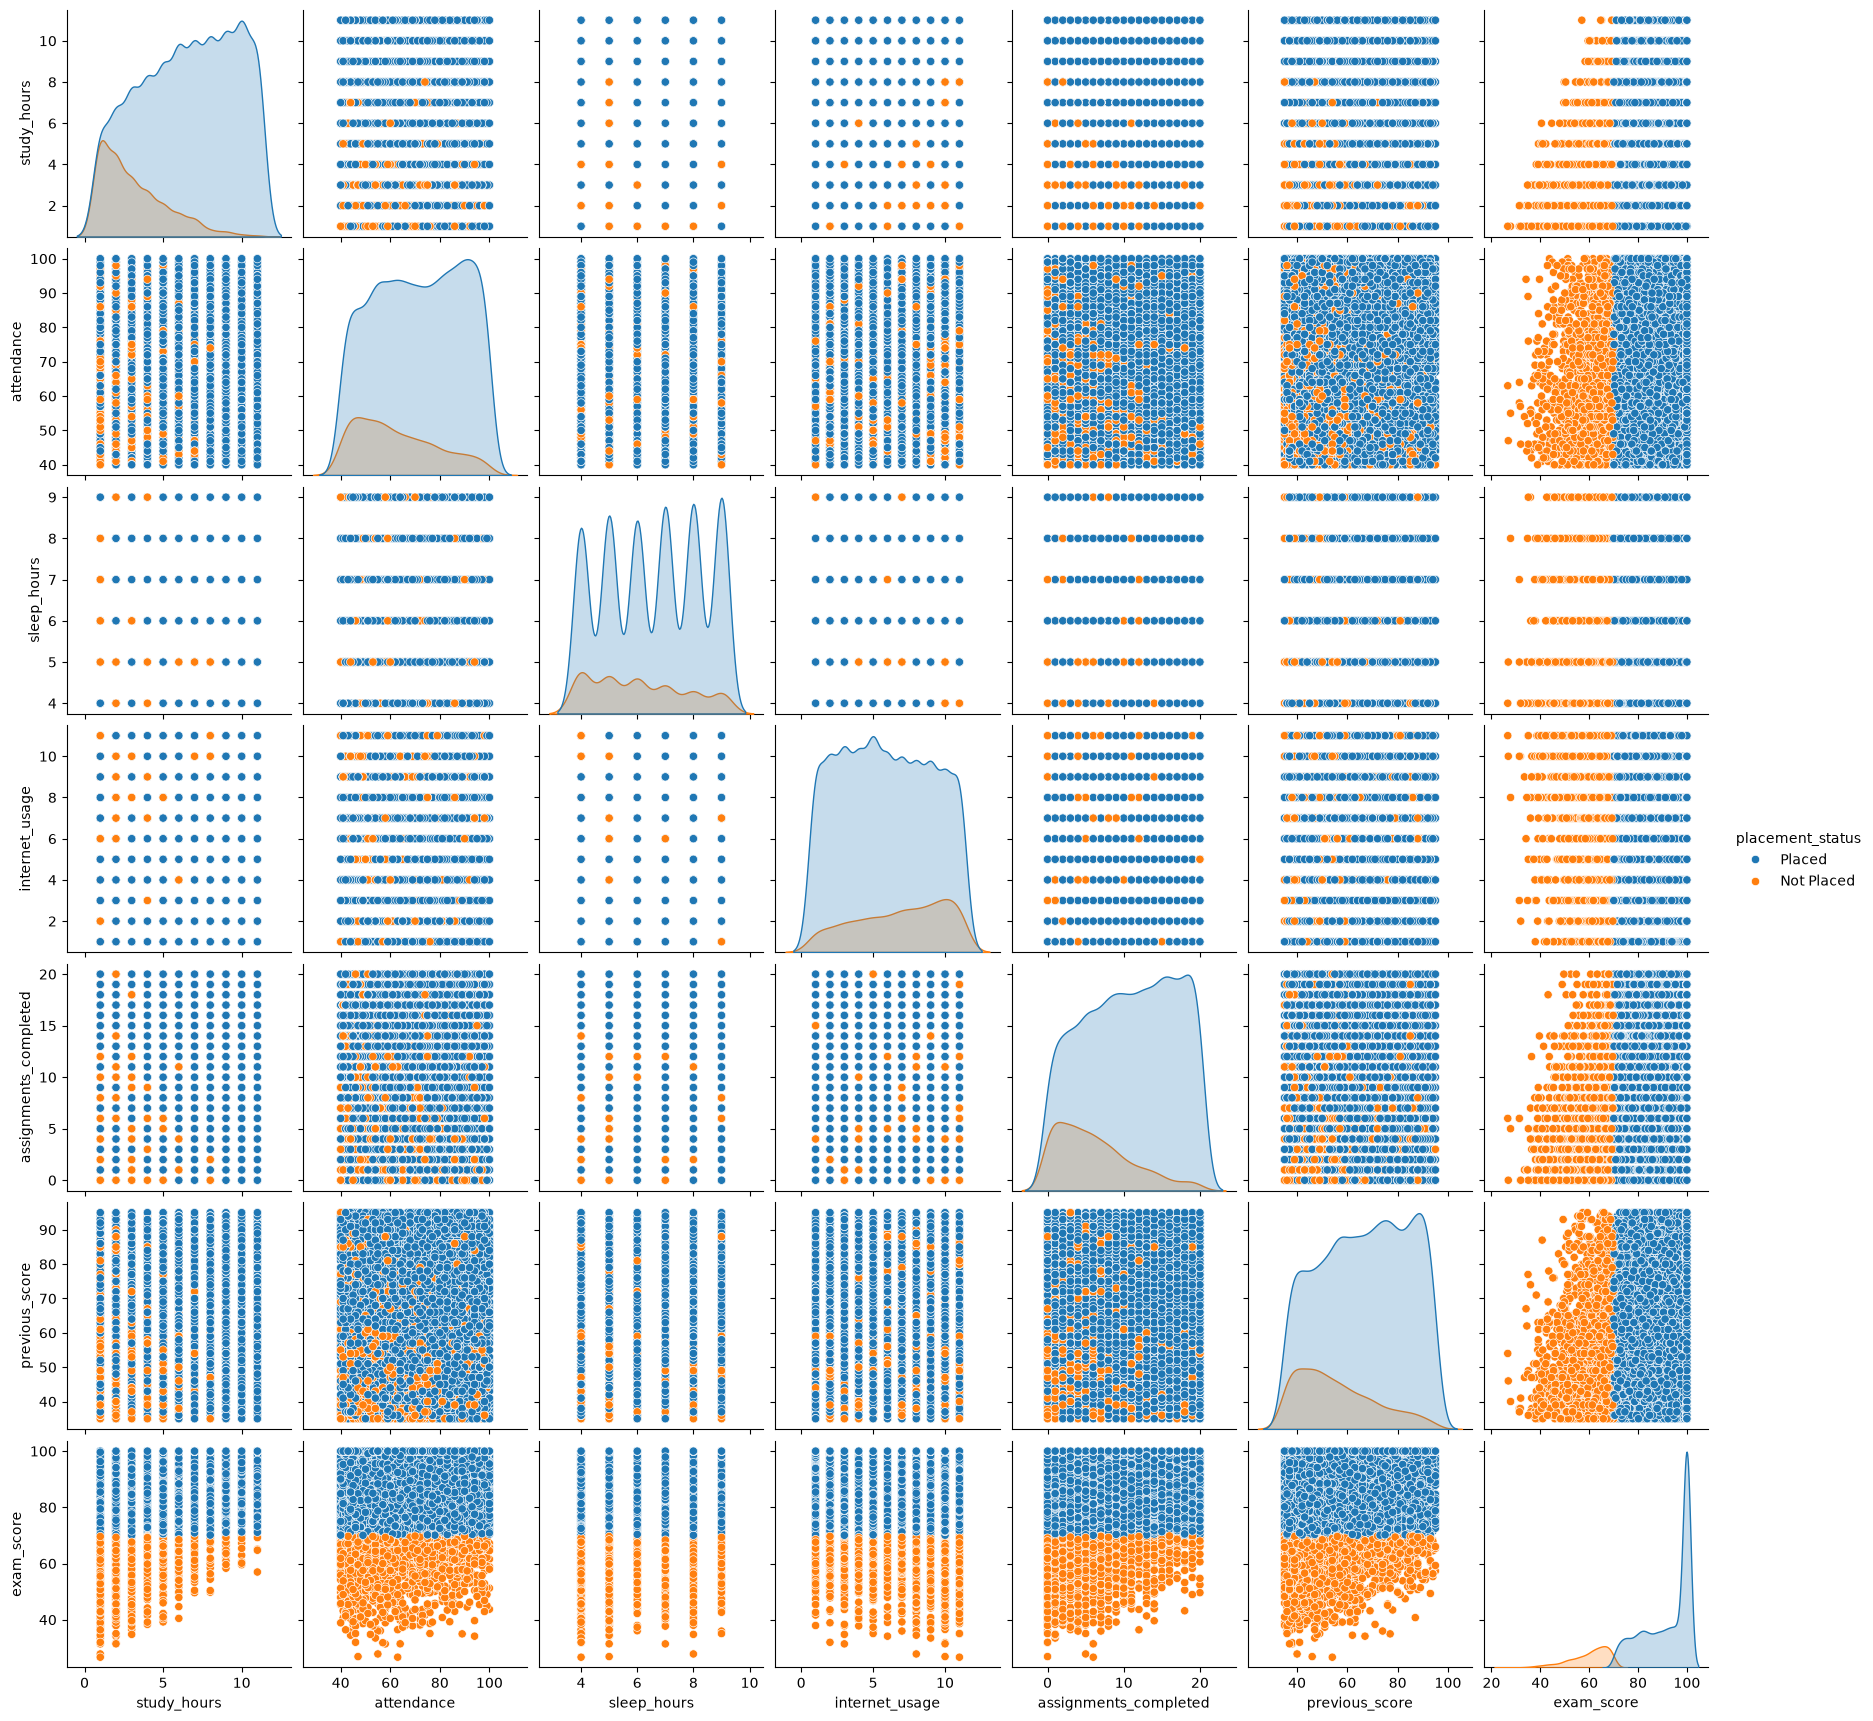

In [19]:
sns.pairplot(df, hue='placement_status')
plt.show()

Berdasarkan hasil di atas variable exam_score memiliki indikasi bahwa dapat memisahkan kedua label

### KESIMPULAN EDA

-  Variabel exam_score memiliki indikasi sebagai salah satu fitur yang berpotensi berpengaruh terhadap prediksi placement_status. Namun, diperlukan analisis lebih lanjut untuk mengetahui hubungan dan kontribusinya terhadap target.

-  Berdasarkan visualisasi histogram, variabel exam_score menunjukkan distribusi yang cenderungiring ke kiri (negative skew). Sementara itu, fitur lainnya memiliki pola distribusi yang bervariasi.

-  Berdasarkan visualisasi boxplot, variabel exam_score menunjukkan adanya indikasi outlier. Namun, data tersebut akan dipertahankan terlebih dahulu karena belum dapat dipastikan apakah nilai tersebut merupakan kesalahan pencatatan atau data yang valid.

-  Berdasarkan visualisasi countplot, sebagian besar siswa berhasil mendapatkan placement (83,56%), sedangkan sebagian kecil lainnya tidak mendapatkan placement (16,44%). Hal ini menunjukkan bahwa dataset memiliki ketidakseimbangan kelas (imbalanced dataset), sehingga perlu diperhatikan pada tahap pemodelan.

# C. PEMODELAN

C1. Split data

In [20]:
def stratified_split(df, kolom_label, train_frac=0.7, random_state=42):
    daftar_train = []
    daftar_test = []

    for label in df[kolom_label].unique():
        df_label = df[df[kolom_label] == label]
        label_train = df_label.sample(frac=train_frac, random_state=random_state, replace=False)
        label_test = df_label.drop(label_train.index)
        daftar_train.append(label_train)
        daftar_test.append(label_test)

    daftar_train = pd.concat(daftar_train).sample(frac=1, random_state=random_state)
    daftar_test = pd.concat(daftar_test).sample(frac=1, random_state=random_state)

    x_tr = daftar_train.drop(columns=kolom_label).values
    y_tr = daftar_train[kolom_label].values
    x_te = daftar_test.drop(columns=kolom_label).values
    y_te = daftar_test[kolom_label].values

    return x_tr, y_tr, x_te, y_te

In [21]:
x_tr, y_tr, x_te, y_te = stratified_split(df, kolom_label='placement_status')

C.2 Membuat Model Decision Tree CART

In [22]:
class DecisionTree:

    def __init__(self, max_depth=5):
        self.tree = None
        self.max_depth = max_depth
        self.feature_types = None
        self.feature_names = None

    # Mengambil kelas yang paling banyak muncul
    def most_common_value(self, y):
        unique, counts = np.unique(y, return_counts=True)
        return unique[np.argmax(counts)]

    # Menghitung Gini Impurity
    def gini_impurity(self, y):
        unique, counts = np.unique(y, return_counts=True)
        probs = counts / len(y)

        return 1 - np.sum(probs ** 2)

    # Menghitung Gini Gain
    def gini_gain(self, parent, left, right):

        left_weight = len(left) / len(parent)
        right_weight = len(right) / len(parent)

        return (
            self.gini_impurity(parent)
            - left_weight * self.gini_impurity(left)
            - right_weight * self.gini_impurity(right)
        )

    # Membangun Decision Tree
    def build_tree(self, x, y, depth):

        # Kondisi berhenti
        if depth >= self.max_depth or len(np.unique(y)) == 1:
            return self.most_common_value(y)

        best_gain = -1
        best_feature = None
        best_split = None
        best_mask = None

        for feature in range(x.shape[1]):

            unique_values = np.unique(x[:, feature])

            # Mencari threshold numerik
            if self.feature_types[feature] == 'numeric':

                values = np.sort(unique_values)

                thresholds = [
                    (values[i] + values[i+1]) / 2
                    for i in range(len(values)-1)
                ]

            # Kategori menggunakan nilai unik
            else:
                thresholds = unique_values

            for value in thresholds:

                if self.feature_types[feature] == 'numeric':
                    left_mask = x[:, feature] <= value
                else:
                    left_mask = x[:, feature] == value

                right_mask = ~left_mask

                # Pastikan kedua cabang tidak kosong
                if not left_mask.any() or not right_mask.any():
                    continue

                gain = self.gini_gain(
                    y,
                    y[left_mask],
                    y[right_mask]
                )

                if gain > best_gain:
                    best_gain = gain
                    best_feature = feature
                    best_split = value
                    best_mask = left_mask

        # Tidak ada split yang menguntungkan
        if best_feature is None or best_gain <= 0:
            return self.most_common_value(y)

        return {
            'feature': best_feature,
            'split': best_split,
            'type': self.feature_types[best_feature],

            'left': self.build_tree(
                x[best_mask],
                y[best_mask],
                depth + 1
            ),

            'right': self.build_tree(
                x[~best_mask],
                y[~best_mask],
                depth + 1
            )
        }

    # Melatih model
    def fit(self, x, y):

        self.feature_names = list(x.columns)

        self.feature_types = [
            'numeric' if pd.api.types.is_numeric_dtype(x[col])
            else 'categorical'
            for col in x.columns
        ]

        x = x.to_numpy(dtype=object)
        y = np.asarray(y)

        self.tree = self.build_tree(x, y, 0)

        return self

    # Prediksi satu data
    def predict_sample(self, sample, node=None):

        if node is None:
            node = self.tree

        # Jika sudah mencapai leaf
        if not isinstance(node, dict):
            return node

        feature = node['feature']
        value = node['split']

        if node['type'] == 'numeric':
            if sample[feature] <= value:
                return self.predict_sample(sample, node['left'])
            else:
                return self.predict_sample(sample, node['right'])

        else:
            if sample[feature] == value:
                return self.predict_sample(sample, node['left'])
            else:
                return self.predict_sample(sample, node['right'])

    # Prediksi banyak data
    def predict(self, x):

        x = x[self.feature_names].to_numpy(dtype=object)

        return np.array([
            self.predict_sample(sample)
            for sample in x
        ])


C.3 Mencari Kedalaman Terbaik Menggunakan Stratified K Fold

In [ ]:
def stratified_kfold(y, n_splits=5, random_state=42):

    rng = np.random.default_rng(random_state)

    unique_classes = np.unique(y)

    class_indices = {
        cls: np.where(y == cls)[0]
        for cls in unique_classes
    }

    folds = [[] for _ in range(n_splits)]

    for cls, indices in class_indices.items():

        rng.shuffle(indices)

        split_indices = np.array_split(indices, n_splits)

        for i in range(n_splits):
            folds[i].extend(split_indices[i])

    for i in range(n_splits):

        val_idx = np.array(folds[i])

        train_idx = np.concatenate([
            np.array(folds[j])
            for j in range(n_splits) if j != i
        ])

        yield train_idx, val_idx

C.4 Membuat function macro f1 untuk menampilkan f1 score pada hasil stratified k fold

In [54]:
def f1_macro(y, y_pred):

    classes = np.unique(np.concatenate([y, y_pred]))
    scores = []

    for cls in classes:

        tp = np.sum((y == cls) & (y_pred == cls))
        fp = np.sum((y != cls) & (y_pred == cls))
        fn = np.sum((y == cls) & (y_pred != cls))

        precision = tp / (tp + fp) if tp + fp > 0 else 0
        recall = tp / (tp + fn) if tp + fn > 0 else 0

        f1 = (
            2 * precision * recall / (precision + recall) if precision + recall > 0 else 0
        )

        scores.append(f1)

    return np.mean(scores)


In [55]:
x_tr = pd.DataFrame(x_tr, columns=df.drop(columns='placement_status').columns)
x_te = pd.DataFrame(x_te, columns=df.drop(columns='placement_status').columns)
y_tr = pd.Series(y_tr)

C.5 Mencoba stratified k_fold menggunakan depth 2 hingga 10

In [56]:
depths = range(2, 11)

for depth in depths:
    scores = []

    for fold, (train_idx, val_idx) in enumerate(stratified_kfold(y_tr), start=1):

        model = DecisionTree(max_depth=depth)

        model.fit(
            x_tr.iloc[train_idx],
            y_tr.iloc[train_idx]
        )

        pred = model.predict(x_tr.iloc[val_idx])

        score = f1_macro(
            y_tr.iloc[val_idx], pred
        )

        scores.append(score)

        print(f"Depth {depth} | Fold {fold}: {score:.4f}")

    print(f"Depth {depth} | Mean F1: {np.mean(scores):.4f}")
    print("-" * 40)

Depth 2 | Fold 1: 1.0000
Depth 2 | Fold 2: 1.0000
Depth 2 | Fold 3: 0.9974
Depth 2 | Fold 4: 1.0000
Depth 2 | Fold 5: 1.0000
Depth 2 | Mean F1: 0.9995
----------------------------------------
Depth 3 | Fold 1: 1.0000
Depth 3 | Fold 2: 1.0000
Depth 3 | Fold 3: 1.0000
Depth 3 | Fold 4: 1.0000
Depth 3 | Fold 5: 1.0000
Depth 3 | Mean F1: 1.0000
----------------------------------------
Depth 4 | Fold 1: 1.0000
Depth 4 | Fold 2: 1.0000
Depth 4 | Fold 3: 1.0000
Depth 4 | Fold 4: 1.0000
Depth 4 | Fold 5: 0.9974
Depth 4 | Mean F1: 0.9995
----------------------------------------
Depth 5 | Fold 1: 1.0000
Depth 5 | Fold 2: 1.0000
Depth 5 | Fold 3: 1.0000
Depth 5 | Fold 4: 1.0000
Depth 5 | Fold 5: 0.9974
Depth 5 | Mean F1: 0.9995
----------------------------------------
Depth 6 | Fold 1: 1.0000
Depth 6 | Fold 2: 1.0000
Depth 6 | Fold 3: 1.0000
Depth 6 | Fold 4: 1.0000
Depth 6 | Fold 5: 1.0000
Depth 6 | Mean F1: 1.0000
----------------------------------------
Depth 7 | Fold 1: 1.0000
Depth 7 | Fold 

Berdasarkan hasil Stratified K-Fold diatas: 
- Depth 2-4 memiliki rata-rata f1 score 0.99
- pada depth 5-9 Mean f1 menjadi 1 atau sempurna
- Namun pada depth 10 mengalami penurunan, yang menunjukkan adanya overfitting pada depths 10

Kesimpulan : Kami memilih depth 5 sebagai parameter decision tree, karena pada kedalaman tersebut model sudah dapat memprediksi dengan cukup baik berdasarkan hasil rata2 f1 score, dan juga jika menggunakan depth 6-9 akan membutuhkan waktu yang lama untuk komputasi model.



C.6 Membuat Model Decision Tree Menggunakan Parameter Kedalaman Pohon 5

In [57]:
model = DecisionTree(6)
model.fit(x_tr, y_tr)

C.7 Membuat Prediksi Untuk Data Train dan Data Test

In [58]:
y_pred_tr = model.predict(x_tr)
y_pred_te = model.predict(x_te)

C.8 Menampilkan Hasil Pohon Decision Tree

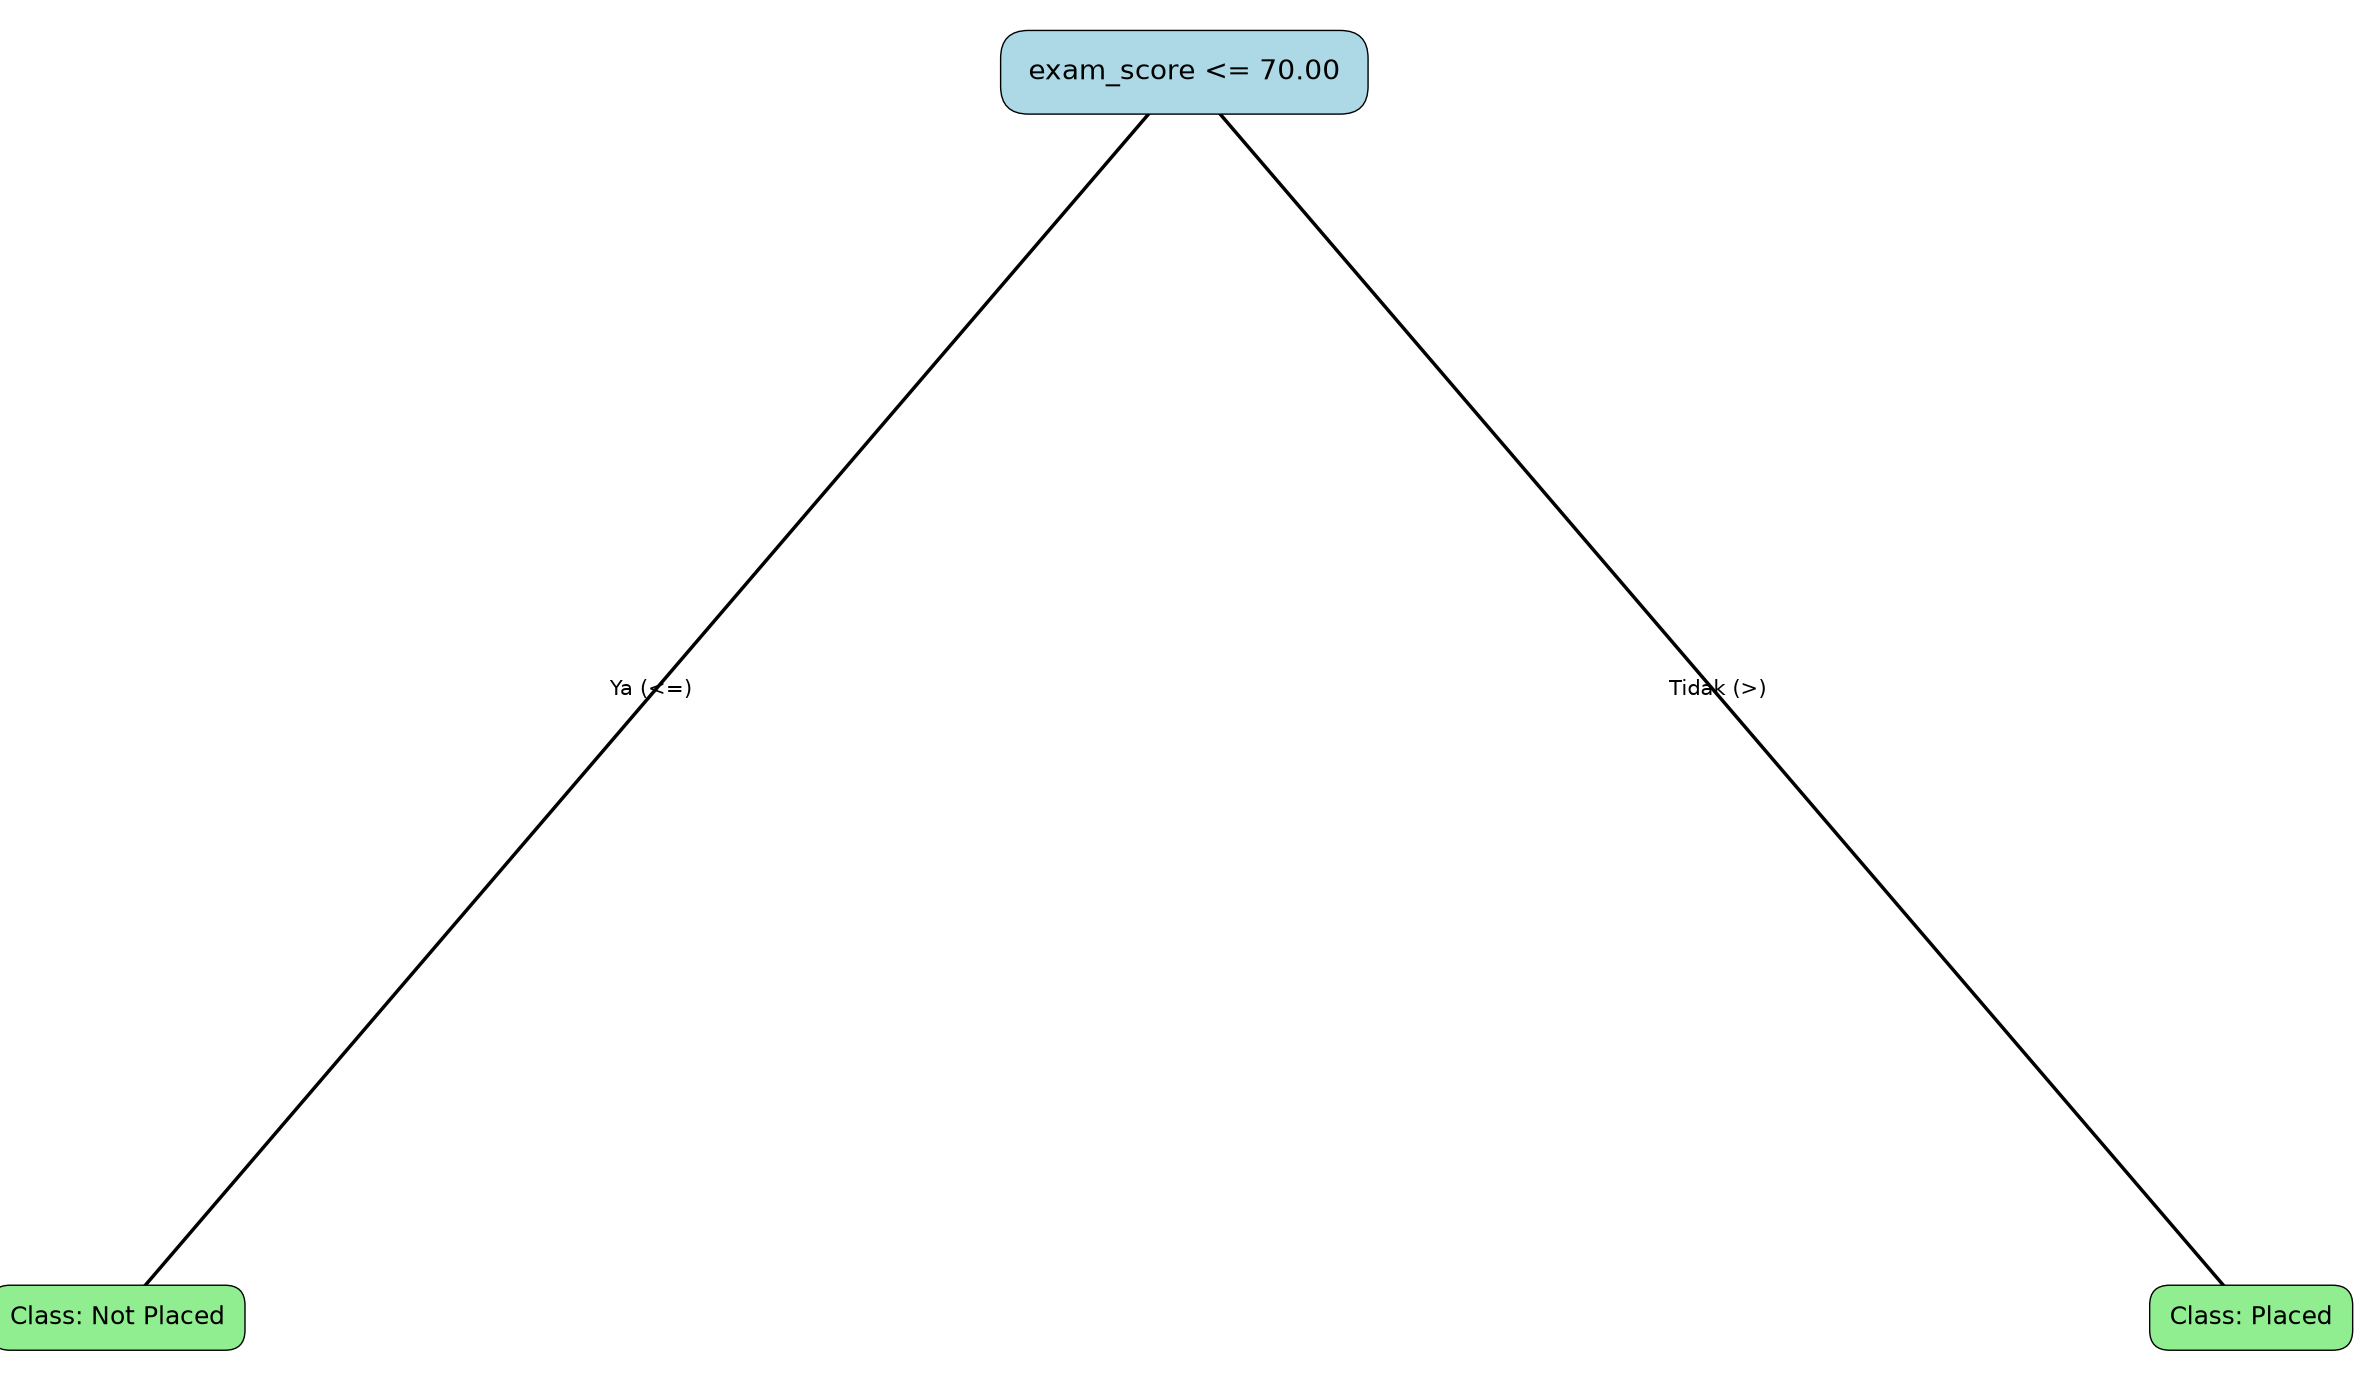

In [68]:

def plot_tree(node, feature_names, x=0.5, y=1,
             dx=0.25, dy=0.12, ax=None,
             depth=0, max_depth=5):

    if ax is None:
        fig, ax = plt.subplots(figsize=(24, 14))
        ax.axis("off")

    # Jika node merupakan leaf
    if not isinstance(node, dict):
        ax.text(
            x, y, f"Class: {node}",
            ha="center",
            va="center",
            fontsize=18,
            bbox=dict(
                boxstyle="round,pad=0.8",
                fc="lightgreen"
            )
        )
        return ax

    # Jika sudah mencapai batas visualisasi
    if depth >= max_depth:
        ax.text(
            x, y, "...",
            ha="center",
            va="center",
            fontsize=18,
            bbox=dict(
                boxstyle="round,pad=0.8",
                fc="orange"
            )
        )
        return ax

    # Mengambil nama fitur dan nilai split
    feature = feature_names[node["feature"]]
    split = node["split"]

    # Menentukan jenis fitur
    if node["type"] == "numeric":
        label = f"{feature} <= {split:.2f}"
        left_label = "Ya (<=)"
        right_label = "Tidak (>)"

    else:
        label = f"{feature} = {split}"
        left_label = "Ya (=)"
        right_label = "Tidak (!=)"

    # Menggambar node keputusan
    ax.text(
        x, y, label,
        ha="center",
        va="center",
        fontsize=20,
        bbox=dict(
            boxstyle="round,pad=1.0",
            fc="lightblue"
        )
    )

    # Cabang kiri
    ax.plot(
        [x, x-dx],
        [y, y-dy],
        "k-",
        linewidth=2.5
    )

    ax.text(
        x-dx/2, y-dy/2,
        left_label,
        ha="center",
        fontsize=15
    )

    plot_tree(
        node["left"], feature_names,
        x-dx, y-dy, dx/2, dy,
        ax, depth+1, max_depth
    )

    # Cabang kanan
    ax.plot(
        [x, x+dx],
        [y, y-dy],
        "k-",
        linewidth=2.5
    )

    ax.text(
        x+dx/2, y-dy/2,
        right_label,
        ha="center",
        fontsize=15
    )

    plot_tree(
        node["right"], feature_names,
        x+dx, y-dy, dx/2, dy,
        ax, depth+1, max_depth
    )

    return ax


# Menampilkan Decision Tree
fig, ax = plt.subplots(figsize=(24, 14))

plot_tree(
    node=model.tree,
    feature_names=model.feature_names,
    ax=ax,
    dx=0.25,
    dy=0.12,
    max_depth=5
)

ax.axis("off")
plt.tight_layout()
plt.show()


Berdasarkan hasil plot diatas, model sudah dapat membedakan 2 label menggunakan fitur exam_score

# D. Evaluasi

D.1 Membuat function evaluasi untuk melihat hasil confussion matrix model

In [91]:
def evaluasi_model(y, y_pred, nama_kelas=None):
    y = np.asarray(y)
    y_pred = np.asarray(y_pred)

    lbl = np.unique(np.concatenate((y, y_pred)))
    if nama_kelas is None:
        nama_kelas = {l: str(l) for l in lbl}
    nama = [nama_kelas[l] for l in lbl]

    cm = pd.DataFrame(np.zeros((len(lbl), len(lbl)), dtype=int), index=lbl, columns=lbl)
    for a, p in zip(y, y_pred):
        cm.loc[a, p] += 1

    akurasi = np.mean(y == y_pred)
    print(f'Akurasi: {akurasi:.2f}')
    print('='*40)

    for l in lbl:
        tp = cm.loc[l,l]
        fp = cm[l].sum() - tp
        fn = cm.loc[l].sum() - tp

        presisi = tp / (tp + fp) if tp + fp > 0 else 0
        recall = tp / (tp + fn) if tp + fn > 0 else 0
        f1 = 2 * presisi * recall / (presisi + recall) if (presisi + recall) > 0 else 0

        print(f'Nama Kelas {nama_kelas[l]}')
        print(f'Presisi: {presisi:.2f}')
        print(f'Recall: {recall:.2f}')
        print(f'F1 Score: {f1:.2f}')
        print(f'-'*50)

    plt.figure(figsize=(5,4))
    sns.heatmap(cm, annot=True, fmt='d', xticklabels=nama, yticklabels=nama, cmap="Blues")
    plt.xlabel('Predict')
    plt.ylabel('Actual')
    plt.show()

    return cm



D.2 Menampilkan Hasil Confussion Matrix Data Train

Akurasi: 1.00
Nama Kelas Not Placed
Presisi: 1.0
Recall: 1.0
F1 Score: 1.0
--------------------------------------------------
Nama Kelas Placed
Presisi: 1.0
Recall: 1.0
F1 Score: 1.0
--------------------------------------------------


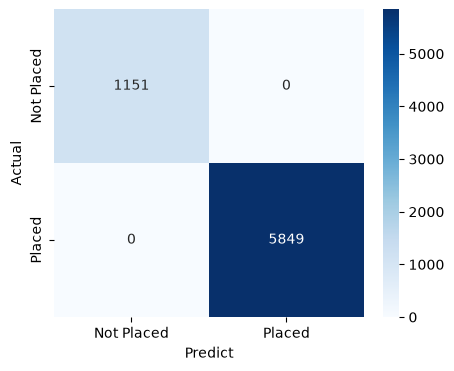

,Not Placed,Placed
Not Placed,1151,0
Placed,0,5849


In [64]:
evaluasi_model(y_tr, y_pred_tr)

D.3 Menampilkan Hasil Confussion Matrix Data test

Akurasi: 1.00
Nama Kelas Not Placed
Presisi: 1.0
Recall: 1.0
F1 Score: 1.0
--------------------------------------------------
Nama Kelas Placed
Presisi: 1.0
Recall: 1.0
F1 Score: 1.0
--------------------------------------------------


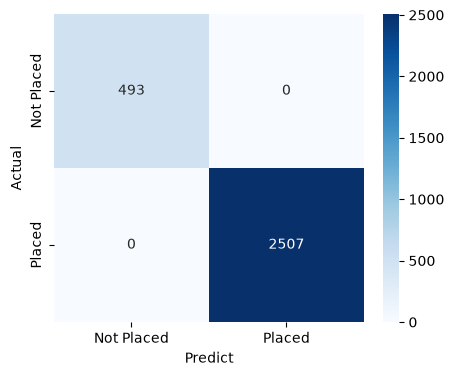

,Not Placed,Placed
Not Placed,493,0
Placed,0,2507


In [69]:
evaluasi_model(y_te, y_pred_te)

Kesimpulan:

- Hasil Model dari data testing dan training memiliki nilai f1 score pada label not placed dan placed sempurna yaitu 1
- Sehingga model sudah dapat memisahkan/memprediksi student masuk pada label placed / not placed berdasarkan data
- Kemungkinan Model mendapat nilai sempurna adalah adanya data leakage, karena model hanya memprediksi menggunakan 1 fitur saja yakni exam score. Kami memutuskan untuk mencoba drop fitur exam_score tersebut agar menghindari data leakage dan mengevaluasi kembali performa model.
- Karena dataset ini sumbernya ada pada kaggle dan author memberikan keterangan " contains 10,000 synthetic student academic records " maka model ini tidak dapat dijadikan sebagai acuan secara real life untuk memprediksi student tersebut Not placed maupun Placed.

# E. Optimasi Model untuk Menghindari Data Leakage

E.1 Drop Kolom Exam Score

In [71]:
df_l = df.drop(columns='exam_score')
df_l.head()

,study_hours,attendance,sleep_hours,internet_usage,assignments_completed,previous_score,placement_status
0,7,56,8,7,10,62,Placed
1,4,69,5,3,8,56,Placed
2,11,60,7,6,10,45,Placed
3,8,99,9,8,4,55,Placed
4,5,52,8,6,8,40,Placed


E.2 Splitting Ulang Menjadi Train dan test

In [82]:
x_tr_n, y_tr_n, x_te_n, y_te_n = stratified_split(df_l, kolom_label='placement_status')

E.3 Mencari ulang parameter kedalaman menggunakan stratified k_fold

In [83]:
x_tr_n = pd.DataFrame(x_tr_n, columns=df_l.drop(columns='placement_status').columns)
x_te_n = pd.DataFrame(x_te_n, columns=df_l.drop(columns='placement_status').columns)
y_tr_n = pd.Series(y_tr_n)

In [84]:
depths = range(2, 11)

for depth in depths:
    scores = []

    for fold, (train_idx, val_idx) in enumerate(stratified_kfold(y_tr_n), start=1):

        model = DecisionTree(max_depth=depth)

        model.fit(
            x_tr_n.iloc[train_idx],
            y_tr_n.iloc[train_idx]
        )

        pred = model.predict(x_tr.iloc[val_idx])

        score = f1_macro(
            y_tr_n.iloc[val_idx], pred
        )

        scores.append(score)

        print(f"Depth {depth} | Fold {fold}: {score:.4f}")

    print(f"Depth {depth} | Mean F1: {np.mean(scores):.4f}")
    print("-" * 40)

Depth 2 | Fold 1: 0.7001
Depth 2 | Fold 2: 0.7315
Depth 2 | Fold 3: 0.7120
Depth 2 | Fold 4: 0.7039
Depth 2 | Fold 5: 0.7389
Depth 2 | Mean F1: 0.7173
----------------------------------------
Depth 3 | Fold 1: 0.7113
Depth 3 | Fold 2: 0.7184
Depth 3 | Fold 3: 0.7303
Depth 3 | Fold 4: 0.7183
Depth 3 | Fold 5: 0.6753
Depth 3 | Mean F1: 0.7107
----------------------------------------
Depth 4 | Fold 1: 0.7203
Depth 4 | Fold 2: 0.7253
Depth 4 | Fold 3: 0.6979
Depth 4 | Fold 4: 0.6872
Depth 4 | Fold 5: 0.7555
Depth 4 | Mean F1: 0.7172
----------------------------------------
Depth 5 | Fold 1: 0.7426
Depth 5 | Fold 2: 0.7704
Depth 5 | Fold 3: 0.7386
Depth 5 | Fold 4: 0.7541
Depth 5 | Fold 5: 0.7256
Depth 5 | Mean F1: 0.7462
----------------------------------------
Depth 6 | Fold 1: 0.7492
Depth 6 | Fold 2: 0.7679
Depth 6 | Fold 3: 0.7352
Depth 6 | Fold 4: 0.7450
Depth 6 | Fold 5: 0.7217
Depth 6 | Mean F1: 0.7438
----------------------------------------
Depth 7 | Fold 1: 0.7547
Depth 7 | Fold 

Berdasarkan Hasil Diatas:

- Nilai rata2 F1 score dari kedalaman 2 - 5 memiliki kenaikan score, namun pada kedalaman 6 mengalami pengurangan nilai yang kecil
- Untuk kedalaman 7 - 8 Mengalami kenaikan, namun pada depth 9 - 10 mengalami penurunan lagi hal ini terindikasi untuk depth 9-10 mengalami overfitting

Kesimpulan Pengambilan Parameter Kedalaman :

Kami memutuskan untuk memilih kedalaman 8, karena memiliki rata2 nilai f1 score yang paling tinggi dibandingkan dengan kedalaman yang lain

E.4 Training Kembali Model Decision Tree

In [86]:
model_baru = DecisionTree(8)
model_baru.fit(x_tr_n, y_tr_n)

E.5 Prediksi Kembali Menggunakan Model Decision Tree yang sudah melalui proses optimasi model

In [87]:
y_pred_tr_br = model_baru.predict(x_tr_n)
y_pred_te_br = model_baru.predict(x_te_n)

In [94]:
x_tr_n

,study_hours,attendance,sleep_hours,internet_usage,assignments_completed,previous_score
0,2,93,7,7,3,52
1,6,64,4,3,19,51
2,2,82,5,9,19,62
3,11,55,9,3,16,90
4,5,55,5,11,20,94
...,...,...,...,...,...,...
6995,11,67,4,1,6,84
6996,11,80,8,2,7,88
6997,7,83,5,7,12,90
6998,5,68,8,7,19,92


E.6 Menampilkan Hasil Plot Pohon setelah optimasi model


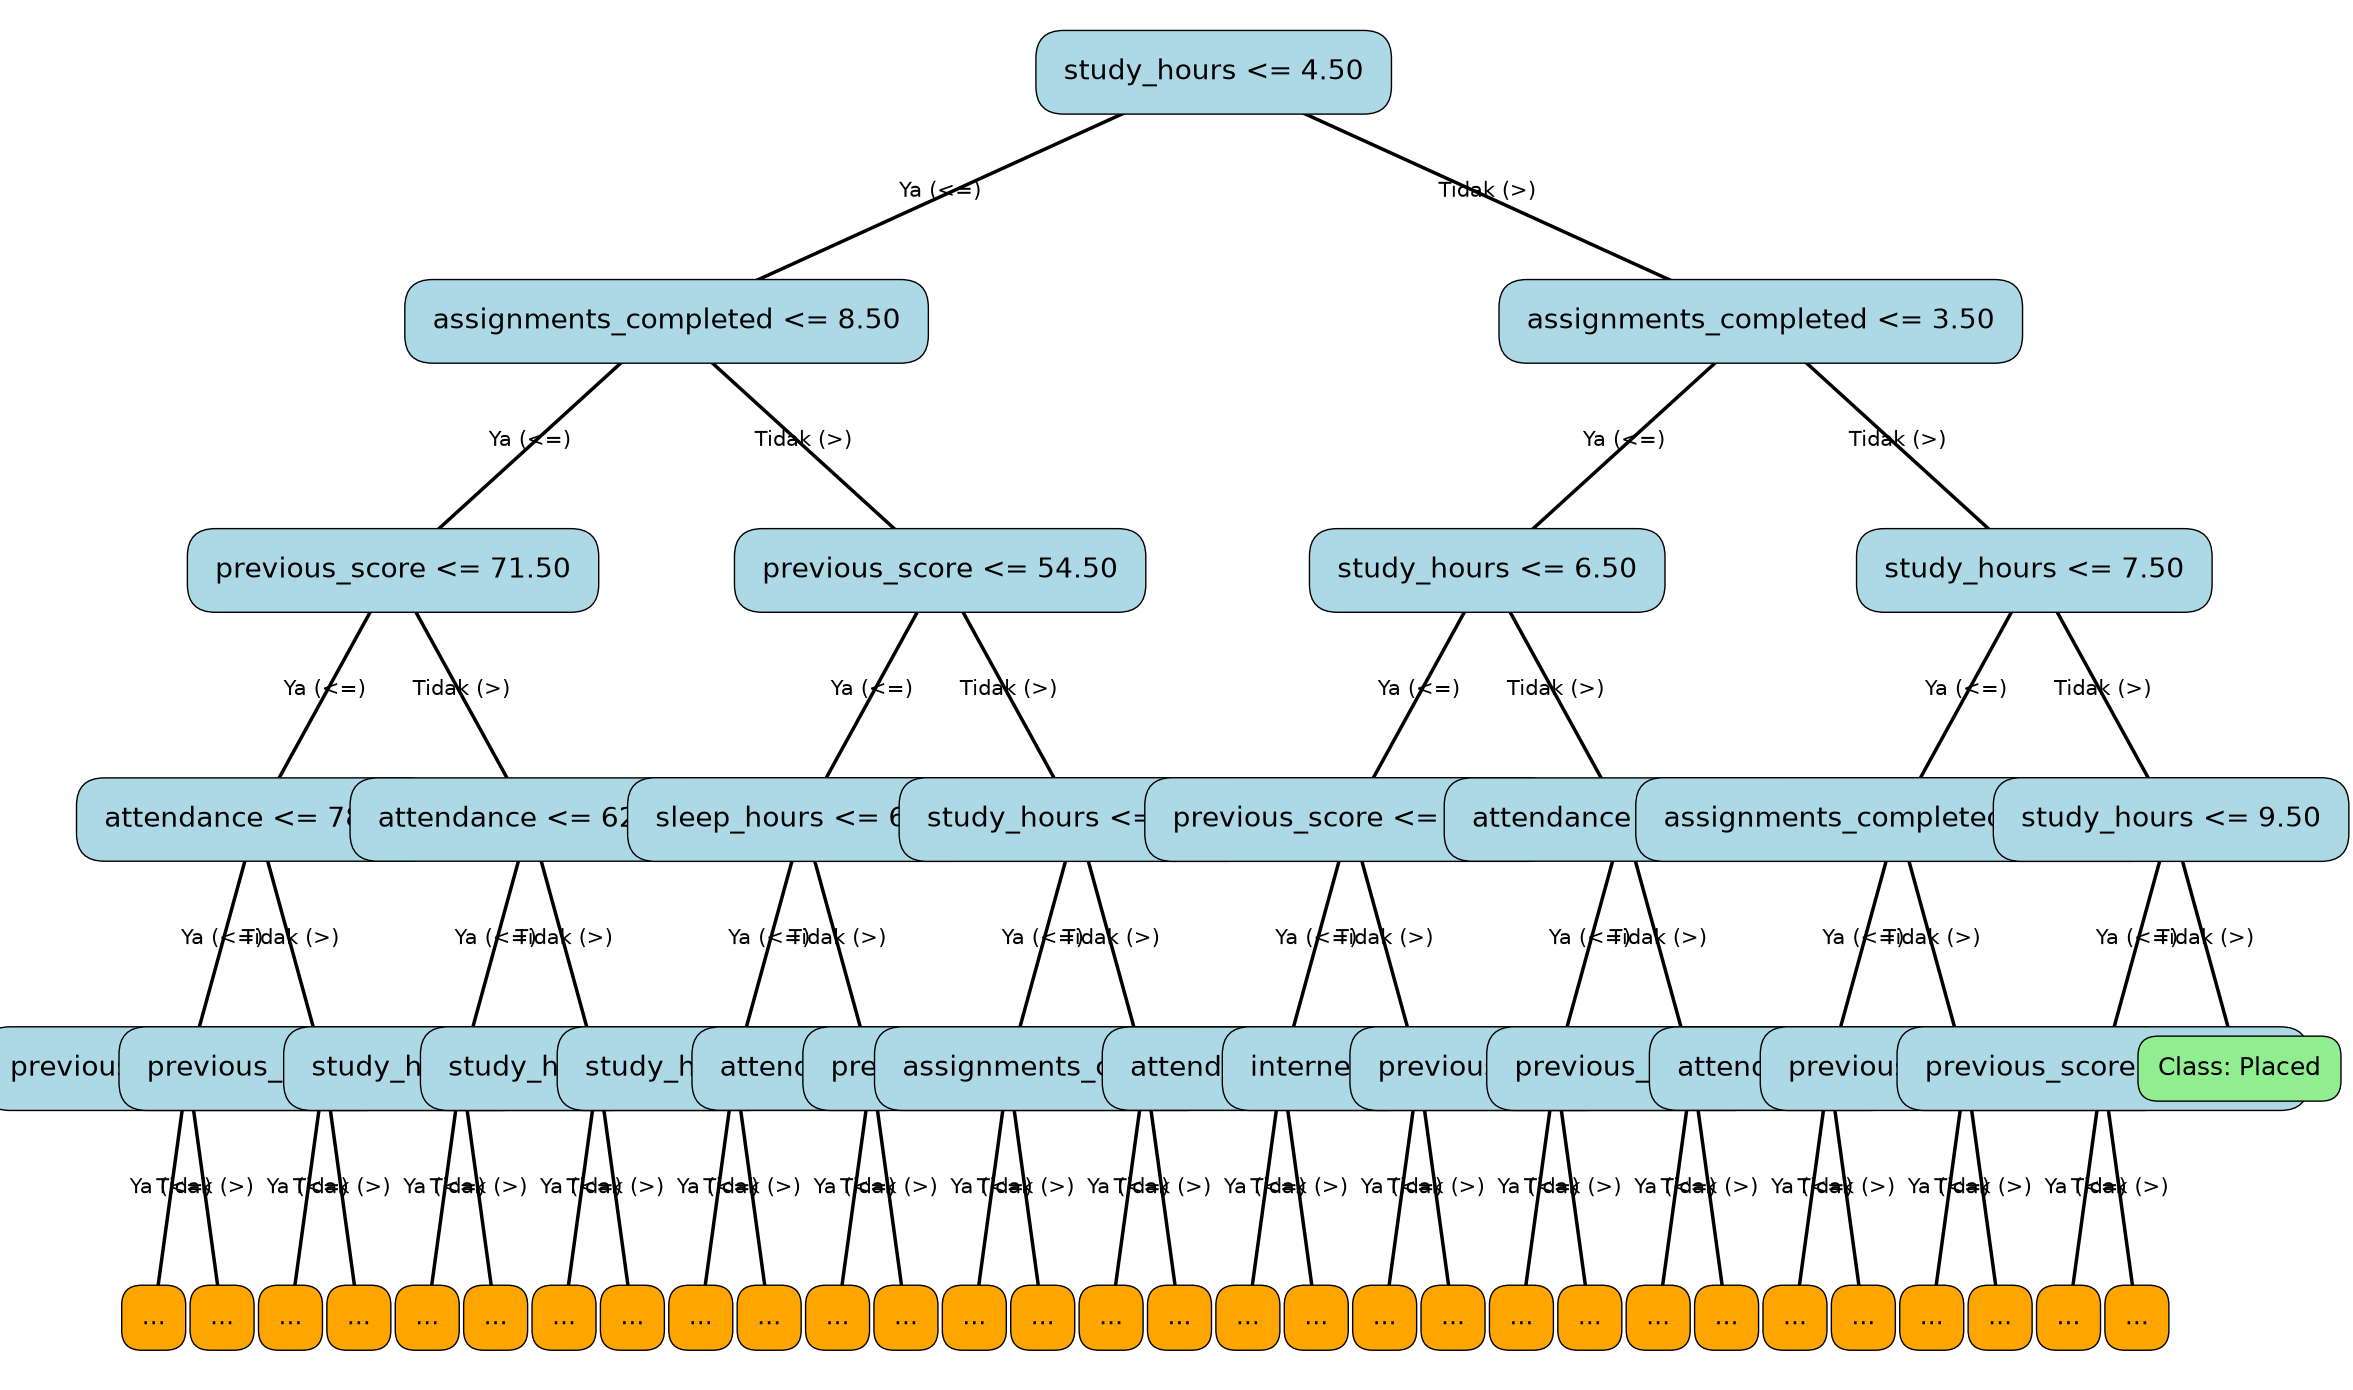

In [89]:
fig, ax = plt.subplots(figsize=(24, 14))

plot_tree(
    node=model_baru.tree,
    feature_names=model_baru.feature_names,
    ax=ax,
    dx=0.25,
    dy=0.12,
    max_depth=5
)

ax.axis("off")
plt.tight_layout()
plt.show()


Berdasarkan hasil diatas:

- Root node berubah menjadi study hours, yang menandakan study hours menjadi fitur terbaik model.
- Diikuti dengan assignments_completed, previous_score, attendance, sleep_hours, digunakan menjadi percabangan berikutnya untuk membantu model membedakan kelas placed atau not placed.


E.7 Menampilkan Confussion Matrix data train

Akurasi: 0.92
Nama Kelas Not Placed
Presisi: 0.80
Recall: 0.71
F1 Score: 0.75
--------------------------------------------------
Nama Kelas Placed
Presisi: 0.94
Recall: 0.97
F1 Score: 0.95
--------------------------------------------------


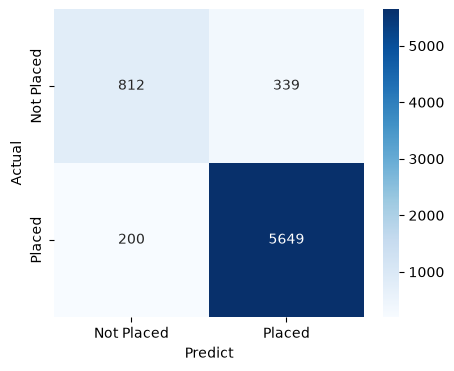

,Not Placed,Placed
Not Placed,812,339
Placed,200,5649


In [92]:
evaluasi_model(y_tr_n, y_pred_tr_br)

E.8 Menampilkan Hasil Confussion Matrix data test

Akurasi: 0.88
Nama Kelas Not Placed
Presisi: 0.65
Recall: 0.57
F1 Score: 0.61
--------------------------------------------------
Nama Kelas Placed
Presisi: 0.92
Recall: 0.94
F1 Score: 0.93
--------------------------------------------------


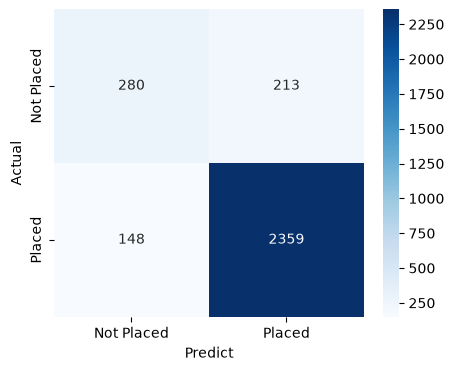

,Not Placed,Placed
Not Placed,280,213
Placed,148,2359


In [93]:
evaluasi_model(y_te_n, y_pred_te_br)

Kesimpulan:

- Setelah fitur exam score dihapus model memiliki indikasi data leakage telah dikurangi. Model Mampu memprediksi/membedakan label not placed maupun placed dengan baik.
- Namun model seringkali meleset/salah menebak untuk label not placed, dibuktikan dengan nilai f1 score yang lumayan kurang yaitu di angka 0.65. Hal tersebut terjadi karena data pada label mengalami ketidakseimbangan kelas (imbalanced data, Minoritas pada kelas Not Placed dan Mayoritas pada kelas placed), sehingga hal tersebut menjadikan model hanya dapat belajar/memprediksi label mayoritas.
- Sekali lagi, karena data ini adalah data buatan/sintesis maka model ini tidak bisa digunakan sebagai acuan siswa untuk memprediksi Not placed maupun Placed.

# E. Graphical User Interface

E.1 Import Library Tambahan

In [99]:
from tkinter import *
from tkinter import messagebox

def submit():
    try:
        hours = float(entryhours.get())
        attendance = float(entryattendance.get())
        sleep = float(entrysleep.get())
        internet = float(entryinternet.get())
        assignment = float(entryassignment.get())
        prescore = float(entryprescore.get())
    except ValueError:
        messagebox.showerror('Error', 'Masukkan input dengan benar.')

    df_baru = pd.DataFrame(data={
        'study_hours': [hours],
        'attendance': [attendance],
        'sleep_hours': [sleep],
        'internet_usage': [internet],
        'assignments_completed': [assignment],
        'previous_score': [prescore]
    })

    y_pred_baru = model_baru.predict(df_baru)

    messagebox.showinfo('Prediksi', f'Prediksi Siswa adalah {y_pred_baru[0]}\n\n' 'DISCLAIMER: Prediksi ini menggunakan data sintetis, bukan data asli.')

window = Tk()
window.title('Student placement status predict')
window.configure(bg='brown')
window.geometry('450x450')

judul_label = Label(window, text='Student placement status predict', font=('Arial', '15', 'bold'), bg='brown')
judul_label.pack(pady=12)

frame1 = Frame(window, bg='brown')
frame1.pack()

hours_label = Label(frame1, text='Masukan Jam Belajar', font=('Arial', '13'), bg='brown')
hours_label.grid(row=0, column=0, pady=12)
entryhours = Entry(frame1)
entryhours.grid(row=0, column=1, pady=12)

attendance_label = Label(frame1, text='Masukan total Kehadiran', font=('Arial', '13'), bg='brown')
attendance_label.grid(row=1, column=0, pady=12)
entryattendance = Entry(frame1)
entryattendance.grid(row=1, column=1, pady=12)

sleep_label = Label(frame1, text='Masukan jam tidur', font=('Arial', '13'), bg='brown')
sleep_label.grid(row=2, column=0, pady=12)
entrysleep = Entry(frame1)
entrysleep.grid(row=2, column=1, pady=12)

internet_label = Label(frame1, text='Masukan jam penggunaan internet', font=('Arial', '13'), bg='brown')
internet_label.grid(row=3, column=0, pady=12, padx=8)
entryinternet = Entry(frame1)
entryinternet.grid(row=3, column=1, pady=12)

assignment_label = Label(frame1, text='Masukan jumlah ketuntasan tugas', font=('Arial', '13'), bg='brown')
assignment_label.grid(row=4, column=0, pady=12)
entryassignment = Entry(frame1)
entryassignment.grid(row=4, column=1, pady=12)

prescore_label = Label(frame1, text='Masukan nilai sebelumnya', font=('Arial', '13'), bg='brown')
prescore_label.grid(row=5, column=0, pady=12)
entryprescore = Entry(frame1)
entryprescore.grid(row=5, column=1, pady=12)

submt = Button(window, text='Prediksi', relief=FLAT, background='white', font=('Arial', 14, 'bold'), command=submit)
submt.pack(pady=25)

window.mainloop()

